<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 106A · Optimización multiobjetivo: Pareto y decisiones industriales</span>

**Sesión 3 · Segunda lección · 40 minutos en clase (ampliaciones para estudio autónomo)**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 106 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Por qué la configuración que minimiza la energía puede ser una mala decisión para una red de transporte de hidrocarburos?

**Fuentes directas:** programa aprobado de la sesión 3, cuaderno `105_ar_Optimizacion_Bayesiana.ipynb`, documentación de Hydro-Lab S2.11 y la arquitectura G2.4. Los experimentos son **sintéticos**, no mediciones industriales ni resultados ejecutados en Hydro-Lab.

## Ruta de la lección

1. Una decisión con dos objetivos.
2. Dominancia, Pareto y factibilidad.
3. Construcción de un laboratorio sintético sencillo.
4. Elegir una estrategia: normalización, pesos y método ε-restricción.
5. Probar la decisión en otro escenario.
6. Relación con Hydro-Lab, PPO y optimización bayesiana.
7. Actividades guiadas.
8. Más de dos objetivos y lecturas complementarias.

**Tiempo sugerido:** 50–60 minutos, ajustable al ritmo del grupo.


# <span style="color:#174ea6"> 1. ¿Qué significa optimizar dos cosas?</span>

Operamos una estación que transporta **hidrocarburo**. Nos interesan dos indicadores:

- **Energía consumida (kWh):** queremos menos.
- **Déficit de transporte (m³):** hidrocarburo programado que no logramos transportar; también queremos menos.

Una estrategia puede ahorrar energía y, a la vez, dejar más hidrocarburo sin transportar. Por eso no siempre existe una única «mejor» estrategia.

## 1.1 Cinco estrategias y dos números por estrategia

| Estrategia | Energía (kWh) ↓ | Déficit (m³) ↓ |
|:--:|--:|--:|
| A | 10 | 40 |
| B | 15 | 20 |
| C | 20 | 10 |
| D | 25 | 15 |
| E | 30 | 0 |

**Pregunta:** si solo importara ahorrar energía, ¿cuál escogerías? **A**. Si solo importara eliminar el déficit, ¿cuál? **E**. Esa diferencia explica por qué necesitamos dos objetivos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos ficticios que usaremos durante toda la primera parte.
datos = pd.DataFrame({
    "estrategia": ["A", "B", "C", "D", "E"],
    "energia_kwh": [10, 15, 20, 25, 30],
    "deficit_m3": [40, 20, 10, 15, 0],
})
print(datos.to_string(index=False))

estrategia  energia_kwh  deficit_m3
         A           10          40
         B           15          20
         C           20          10
         D           25          15
         E           30           0



## <span style="color:#bd232b">1.2 Dibujemos las cinco estrategias</span>

Cada punto corresponde a **una estrategia**. Hacia la izquierda consumimos menos energía; hacia abajo dejamos menos hidrocarburo sin transportar. En general, queremos acercarnos a la **esquina inferior izquierda**.

En el gráfico siguiente no hay un «ganador» automático.

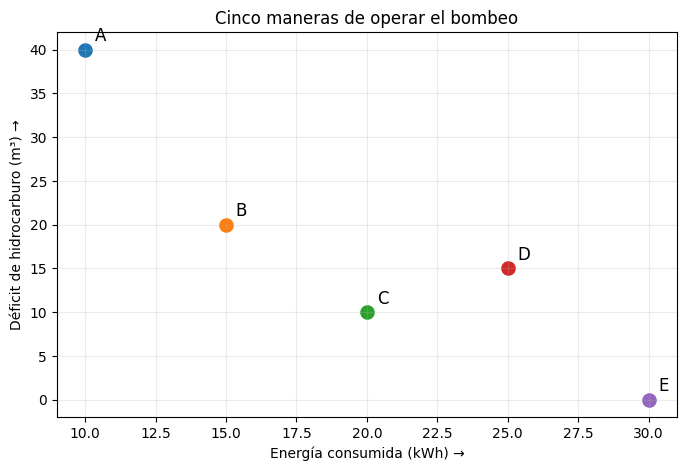

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, fila in datos.iterrows():
    ax.scatter(fila.energia_kwh, fila.deficit_m3, s=90)
    ax.annotate(fila.estrategia, (fila.energia_kwh, fila.deficit_m3), xytext=(7, 6), textcoords="offset points", fontsize=12)
ax.set(xlabel="Energía consumida (kWh) →", ylabel="Déficit de hidrocarburo (m³) →", title="Cinco maneras de operar el bombeo")
ax.grid(alpha=.25)
plt.show()


# <span style="color:#174ea6"> 2. Dominancia, Pareto y restricciones</span>

## <span style="color:#bd232b">2.1 ¿Cuándo una estrategia domina a otra?</span>
Comparemos **C** y **D**:

- C consume **20 kWh**, mientras D consume **25 kWh**.
- C deja **10 m³** de déficit, mientras D deja **15 m³**.

C es mejor en ambos indicadores. Decimos: **C domina a D**.

**Regla sencilla:** una estrategia domina a otra cuando **no es peor en ninguno** de los objetivos y **es mejor en al menos uno**.

**Ahora compara B y C:** B ahorra energía (15 frente a 20), pero C reduce el déficit (10 frente a 20). **Ninguna domina a la otra**.

**Comprobación:** ¿por qué C domina a D, pero no domina a B? Responde antes de continuar.


## <span style="color:#bd232b">2.2 El frente de Pareto</span>

Si eliminamos las estrategias dominadas, quedan **A, B, C y E**. Son las alternativas **no dominadas** entre estas cinco estrategias.

A ese conjunto de resultados lo llamamos **frente de Pareto** (y a las estrategias correspondientes, conjunto de Pareto). La línea que dibujaremos solo ayuda a visualizar las alternativas disponibles: **no significa que todos los puntos intermedios sean opciones reales**.

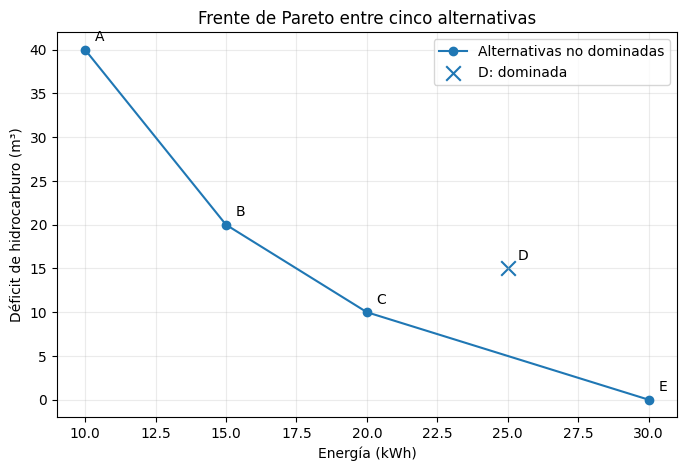

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
pareto_manual = datos[datos.estrategia.isin(["A", "B", "C", "E"])].sort_values("energia_kwh")
ax.plot(pareto_manual.energia_kwh, pareto_manual.deficit_m3, "o-", label="Alternativas no dominadas")
d = datos[datos.estrategia == "D"].iloc[0]
ax.scatter(d.energia_kwh, d.deficit_m3, s=110, marker="x", label="D: dominada")
for _, fila in datos.iterrows():
    ax.annotate(fila.estrategia, (fila.energia_kwh, fila.deficit_m3), xytext=(7, 6), textcoords="offset points")
ax.set(xlabel="Energía (kWh)", ylabel="Déficit de hidrocarburo (m³)", title="Frente de Pareto entre cinco alternativas")
ax.legend(); ax.grid(alpha=.25)
plt.show()


## <span style="color:#bd232b">2.3 ¿Y si existe una restricción?</span>
La empresa exige: **el déficit no puede superar 15 m³**.

- A (40 m³) y B (20 m³) quedan fuera: **no son factibles**.
- C (10 m³), D (15 m³) y E (0 m³) sí son factibles.
- Entre las factibles, **D sigue dominada por C**.

**Diferencia clave:** «factible» significa que cumple las reglas. «No dominada» significa que ninguna otra alternativa factible es al menos tan buena en todo y mejor en algo.

**Pregunta:** si imponemos ese límite, ¿cuáles quedan como alternativas no dominadas? **C y E**.

Estrategias factibles: C, D, E


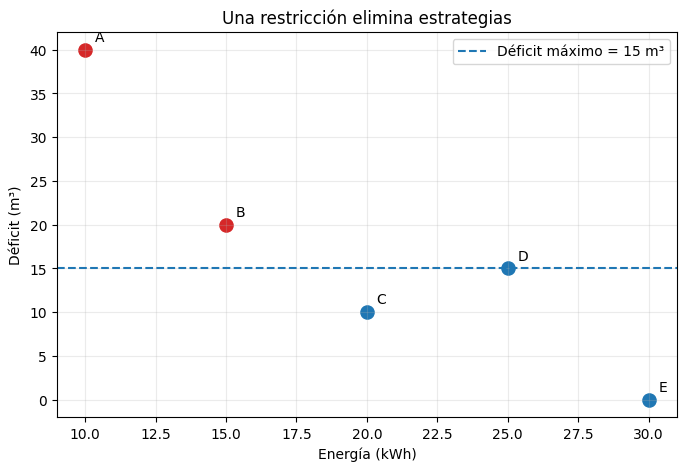

In [4]:
LIMITE_DEFICIT = 15
factibles = datos[datos.deficit_m3 <= LIMITE_DEFICIT].copy()
print("Estrategias factibles:", ", ".join(factibles.estrategia))
fig, ax = plt.subplots(figsize=(8, 5))
for _, fila in datos.iterrows():
    color = "tab:blue" if fila.deficit_m3 <= LIMITE_DEFICIT else "tab:red"
    ax.scatter(fila.energia_kwh, fila.deficit_m3, color=color, s=90)
    ax.annotate(fila.estrategia, (fila.energia_kwh, fila.deficit_m3), xytext=(7, 6), textcoords="offset points")
ax.axhline(LIMITE_DEFICIT, linestyle="--", label="Déficit máximo = 15 m³")
ax.set(xlabel="Energía (kWh)", ylabel="Déficit (m³)", title="Una restricción elimina estrategias")
ax.legend(); ax.grid(alpha=.25)
plt.show()


## <span style="color:#bd232b">2.4 La misma idea, ahora con símbolos</span>

Llamemos $x$ a una estrategia. Definimos:

- $f_1(x)$ = energía consumida por esa estrategia.
- $f_2(x)$ = déficit de transporte de hidrocarburo.

Queremos **minimizar ambos**:

$$\min_x\big(f_1(x),\,f_2(x)\big).$$

No estamos sumando todavía. La expresión dice: «busca estrategias que reduzcan estos dos indicadores».

**Dominancia:** $x$ domina a $y$ si $f_1(x)\leq f_1(y)$ y $f_2(x)\leq f_2(y)$, y **al menos una** de esas desigualdades es estricta.

**Restricción del ejemplo:** $f_2(x)\leq 15$. No se requiere más matemática para aplicar esta definición.


## <span style="color:#bd232b">2.5 Python: enseñar al computador a comparar</span>

La función siguiente hace exactamente la comparación que acabamos de hacer a mano. Primero pregunta «¿no es peor en nada?» y luego «¿es mejor en algo?». Solo cuando ambas respuestas son **sí**, hay dominancia.

In [5]:
def domina(energia_a, deficit_a, energia_b, deficit_b):
    no_es_peor = (energia_a <= energia_b) and (deficit_a <= deficit_b)
    mejora_algo = (energia_a < energia_b) or (deficit_a < deficit_b)
    return no_es_peor and mejora_algo

print("¿C domina D?", domina(20, 10, 25, 15))
print("¿C domina B?", domina(20, 10, 15, 20))

¿C domina D? True
¿C domina B? False



# <span style="color:#174ea6"> 3. Laboratorio sintético: ¿de dónde salen las estrategias?</span>

Hasta ahora teníamos cinco resultados ya calculados. En un laboratorio, primero elegimos una **configuración de operación** y luego el simulador devuelve sus indicadores.

Para no complicar el curso, usaremos **un único control ficticio**: $u$, intensidad de bombeo, entre 0 y 1.

- $u=0$ significa intensidad baja.
- $u=1$ significa intensidad alta.

Inventamos dos fórmulas **solo para aprender**:

$$E(u)=10+20u$$
$$D(u)=40(1-u)^2$$

Donde $E$ está en kWh y $D$ en m³. Estas fórmulas **no son ecuaciones físicas de un oleoducto**.

**Cálculo a mano:** si $u=0.5$, entonces $E=10+20(0.5)=20$ kWh y $D=40(0.5)^2=10$ m³. Así nace una fila de nuestra tabla.

In [6]:
def evaluar(u):
    energia = 10 + 20*u
    deficit = 40*(1-u)**2
    return energia, deficit

for u in [0, 0.5, 1]:
    e, d = evaluar(u)
    print(f"u={u:.1f}  energía={e:.1f} kWh  déficit={d:.1f} m³")

u=0.0  energía=10.0 kWh  déficit=40.0 m³
u=0.5  energía=20.0 kWh  déficit=10.0 m³
u=1.0  energía=30.0 kWh  déficit=0.0 m³



## <span style="color:#bd232b">3.1 Probemos 21 configuraciones</span>

No necesitamos algoritmos sofisticados: tomamos 21 valores igualmente espaciados de $u$ entre 0 y 1. Para cada valor calculamos energía y déficit.

**Observación:** cuando aumentamos $u$, sube la energía y baja el déficit. El gráfico muestra el compromiso entre ambos objetivos.

   u  energia_kwh  deficit_m3
0.00         10.0        40.0
0.25         15.0        22.5
0.50         20.0        10.0
0.75         25.0         2.5
1.00         30.0         0.0


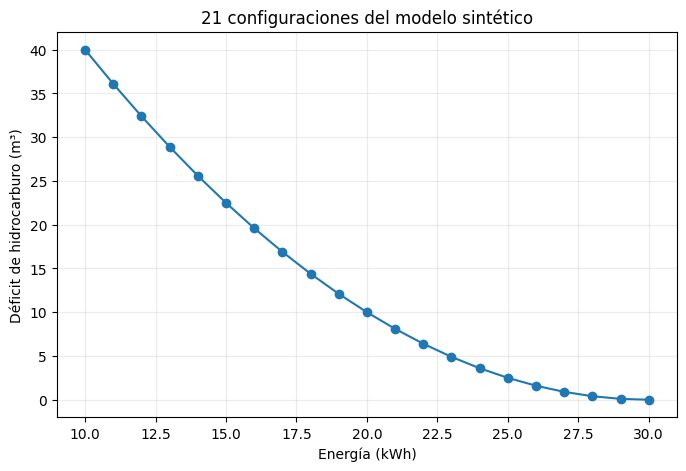

In [7]:
valores_u = np.linspace(0, 1, 21)
experimento = pd.DataFrame([
    {"u": float(u), "energia_kwh": evaluar(u)[0], "deficit_m3": evaluar(u)[1]}
    for u in valores_u
])
print(experimento.iloc[::5].round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(experimento.energia_kwh, experimento.deficit_m3, "o-")
ax.set(xlabel="Energía (kWh)", ylabel="Déficit de hidrocarburo (m³)", title="21 configuraciones del modelo sintético")
ax.grid(alpha=.25)
plt.show()


## <span style="color:#bd232b">3.2 ¿Cómo calculamos Pareto para muchas estrategias?</span>

Para cada candidata, buscamos si **otra** la domina. Si encontramos alguna, descartamos la candidata. Si no encontramos ninguna, la conservamos.

En este modelo sencillo, las 21 configuraciones son no dominadas: para reducir el déficit hay que gastar más energía. **No siempre ocurre así en un modelo real**.

In [8]:
def mascara_pareto(tabla):
    puntos = tabla[["energia_kwh", "deficit_m3"]].to_numpy()
    resultado = []
    for i, p in enumerate(puntos):
        alguna_domina = False
        for j, q in enumerate(puntos):
            if i != j and domina(q[0], q[1], p[0], p[1]):
                alguna_domina = True
                break
        resultado.append(not alguna_domina)
    return np.array(resultado)

experimento["no_dominada"] = mascara_pareto(experimento)
print("Configuraciones no dominadas:", experimento.no_dominada.sum(), "de", len(experimento))

Configuraciones no dominadas: 21 de 21



# <span style="color:#174ea6"> 4. ¿Cómo elegimos entre soluciones de Pareto?</span>

Pareto nos entrega alternativas eficientes, pero **no elige por nosotros**. La decisión depende de las prioridades.

Volvamos a nuestras cinco estrategias, sin imponer todavía la restricción de 15 m³.


## <span style="color:#bd232b">4.1 ¿Por qué no sumar directamente kWh y m³?</span>

No tiene sentido interpretar $20\text{ kWh}+10\text{ m}^3$ como una medida física. Son unidades distintas. Si queremos construir una **puntuación de preferencia**, primero podemos llevar ambos indicadores a una escala común.

En la tabla original, la energía va de **10 a 30** y el déficit de **0 a 40**.

Normalizamos cada indicador entre 0 y 1:

$$z_E=\frac{E-10}{30-10},\qquad z_D=\frac{D-0}{40-0}.$$

En ambos casos **0 significa el mejor valor de la tabla y 1 el peor**.

Para C, $E=20$ y $D=10$:

- Energía normalizada: $(20-10)/20=0.50$.
- Déficit normalizado: $10/40=0.25$.

**Importante:** esos mínimos y máximos son referencias elegidas para esta tabla; si cambian, también pueden cambiar las puntuaciones.

In [9]:
comparacion = datos.copy()
comparacion["energia_norm"] = (comparacion.energia_kwh - 10)/20
comparacion["deficit_norm"] = comparacion.deficit_m3/40
print(comparacion.round(3).to_string(index=False))

estrategia  energia_kwh  deficit_m3  energia_norm  deficit_norm
         A           10          40          0.00         1.000
         B           15          20          0.25         0.500
         C           20          10          0.50         0.250
         D           25          15          0.75         0.375
         E           30           0          1.00         0.000



## <span style="color:#bd232b">4.2 Una puntuación con pesos</span>

Supongamos que la empresa decide dar **30 % de importancia a la energía** y **70 % al déficit**.

La puntuación será:

$$S(x)=0.30z_E(x)+0.70z_D(x).$$

**Elegimos la puntuación más baja.** Los pesos expresan preferencias, **no probabilidades**.

Cálculo manual para C:

$$S(C)=0.30(0.50)+0.70(0.25)=0.325.$$

**Pregunta:** ¿cuánto vale la puntuación de E? Como su energía normalizada es 1 y su déficit normalizado es 0, vale $0.30$. Por eso E gana a C con estos pesos: el déficit importa mucho.

In [10]:
PESO_ENERGIA = 0.30
PESO_DEFICIT = 0.70
comparacion["puntuacion"] = (PESO_ENERGIA*comparacion.energia_norm +
                             PESO_DEFICIT*comparacion.deficit_norm)
print(comparacion[["estrategia", "puntuacion"]].sort_values("puntuacion").round(3).to_string(index=False))
print("Elegida:", comparacion.loc[comparacion.puntuacion.idxmin(), "estrategia"])

estrategia  puntuacion
         E       0.300
         C       0.325
         B       0.425
         D       0.487
         A       0.700
Elegida: E



## <span style="color:#bd232b">4.3 Cambiemos las prioridades</span>


¿Qué ocurre si ahora la energía pesa 70 % y el déficit 30 %? **No cambiamos las estrategias**, solo las preferencias.

El gráfico siguiente permite observar cómo cambia la puntuación de cada estrategia según el peso de energía. El peso del déficit siempre será $1-w$.

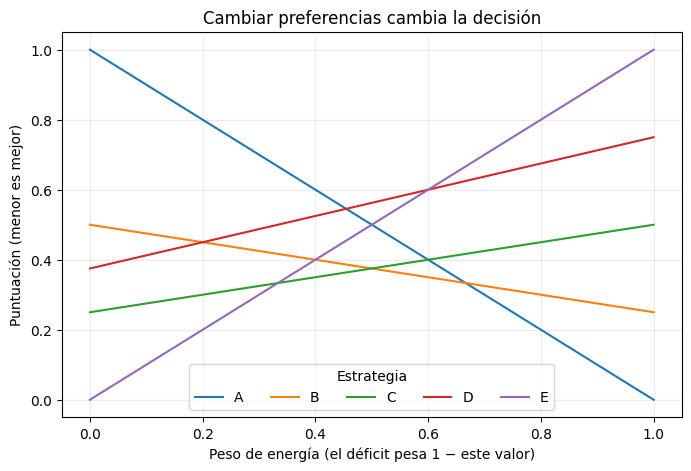

In [11]:
pesos = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(8, 5))
for _, fila in comparacion.iterrows():
    puntuaciones = pesos*fila.energia_norm + (1-pesos)*fila.deficit_norm
    ax.plot(pesos, puntuaciones, label=fila.estrategia)
ax.set(xlabel="Peso de energía (el déficit pesa 1 − este valor)", ylabel="Puntuación (menor es mejor)", title="Cambiar preferencias cambia la decisión")
ax.legend(title="Estrategia", ncol=5); ax.grid(alpha=.25)
plt.show()


## <span style="color:#bd232b">4.4 Otra manera de decidir: método ε-restricción</span>

En lugar de sumar indicadores, podemos decir:

> «Quiero gastar la **menor energía posible**, pero acepto como máximo **15 m³** de déficit».

Esto se escribe:

$$\min_x E(x)\quad\text{sujeto a}\quad D(x)\leq 15.$$

Con las cinco estrategias iniciales:

1. A y B incumplen el límite.
2. C, D y E cumplen.
3. Entre esas tres, **C consume menos energía** (20 kWh).

Por tanto, **C es la elegida** con esta regla.

Esta forma de decidir es útil cuando un indicador representa un límite operativo que **no estamos dispuestos a negociar**.

In [12]:
limite = 15
permitidas = datos[datos.deficit_m3 <= limite]
elegida = permitidas.loc[permitidas.energia_kwh.idxmin()]
print(f"Menor energía con déficit ≤ {limite} m³: estrategia {elegida.estrategia}")
print(f"Energía: {elegida.energia_kwh} kWh; déficit: {elegida.deficit_m3} m³")

Menor energía con déficit ≤ 15 m³: estrategia C
Energía: 20 kWh; déficit: 10 m³



## <span style="color:#bd232b">4.5 Una precaución: los pesos no siempre encuentran todo Pareto</span>

El método de suma ponderada es práctico, pero en ciertos conjuntos **no convexos** algunas alternativas no dominadas nunca son las mejores para ningún par de pesos positivos.

No necesitamos demostrarlo aquí. Basta recordar que **«estar en Pareto» y «ganar con una suma ponderada» no son siempre lo mismo**. El método ε-restricción ofrece otra manera de explorar las alternativas.

**Comprobación:** ¿cuál es la diferencia entre «dar 70 % de peso al déficit» y «exigir déficit ≤ 15 m³»? En el primer caso podemos intercambiar energía por déficit; en el segundo, superar el límite no está permitido.


# <span style="color:#174ea6"> 5. ¿La estrategia elegida funciona en otro escenario?</span>

Hasta ahora decidimos con un solo escenario. Pero la demanda de transporte puede cambiar.

Para entender la **robustez**, tomemos el modelo sintético de la sección 3. Supongamos que en un escenario de mayor demanda el déficit crece un **25 %**. Esta variación es ficticia, elegida para aprender.

**Regla de validación:** seleccionamos con el escenario original y **después** comprobamos qué pasa con la misma configuración en el escenario de prueba. No cambiamos la configuración durante la prueba.

In [13]:
# Selección: mínimo consumo con déficit nominal ≤ 15 m³.
candidatos = experimento[experimento.deficit_m3 <= 15]
seleccion = candidatos.loc[candidatos.energia_kwh.idxmin()]
u_elegido = float(seleccion.u)
e_nominal, d_nominal = evaluar(u_elegido)
d_mayor_demanda = 1.25*d_nominal
print(f"Configuración elegida: u = {u_elegido:.2f}")
print(f"Escenario nominal: energía = {e_nominal:.2f} kWh; déficit = {d_nominal:.2f} m³")
print(f"Escenario de mayor demanda: déficit = {d_mayor_demanda:.2f} m³")
print("¿Cumple límite de 15 m³ en prueba?", d_mayor_demanda <= 15)

Configuración elegida: u = 0.40
Escenario nominal: energía = 18.00 kWh; déficit = 14.40 m³
Escenario de mayor demanda: déficit = 18.00 m³
¿Cumple límite de 15 m³ en prueba? False



## <span style="color:#bd232b">5.1 Dibujemos la comparación de escenarios</span>

El gráfico compara el déficit nominal con el de mayor demanda para la **misma** configuración elegida. La línea punteada marca el límite operativo.

**Interpretación:** si una estrategia cumple el límite en el escenario nominal, pero lo incumple en el nuevo escenario, su selección no es robusta frente a ese cambio.

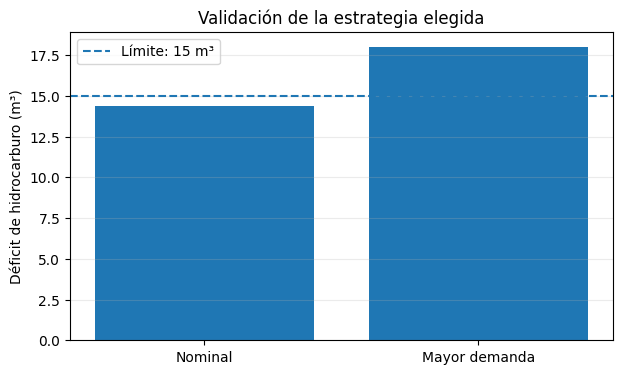

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Nominal", "Mayor demanda"], [d_nominal, d_mayor_demanda])
ax.axhline(15, linestyle="--", label="Límite: 15 m³")
ax.set(ylabel="Déficit de hidrocarburo (m³)", title="Validación de la estrategia elegida")
ax.legend(); ax.grid(axis="y", alpha=.25)
plt.show()


# <span style="color:#174ea6"> 6. Conexión con Hydro-Lab, PPO y optimización bayesiana</span>

**En Hydro-Lab:** una configuración de controlador o una política de operación se ejecuta en un simulador; medimos consumo energético y déficit de transporte de hidrocarburo; comprobamos restricciones; comparamos estrategias y validamos la seleccionada en escenarios distintos.

**PPO:** es un método para **aprender** una política a partir de la interacción con un entorno. La optimización multiobjetivo que acabamos de estudiar permite **evaluar y comparar** políticas o configuraciones según varios indicadores. No son el mismo procedimiento.

**Optimización bayesiana (cuaderno 105):** sirve para decidir **qué configuración conviene evaluar a continuación** cuando cada evaluación cuesta tiempo. Podríamos aplicarla a una puntuación ponderada; estudiar BO multiobjetivo completa requiere otra lección.

**Importante:** este cuaderno usa fórmulas ficticias y **no ejecuta ni modifica Hydro-Lab S2.11**.


# <span style="color:#174ea6"> 7. Actividades guiadas</span>


**Actividad 1 — Dominancia (a mano).** Con la tabla A–E, explica por qué C domina a D y por qué B y C no se dominan.

**Actividad 2 — Restricciones.** Si el déficit máximo permitido fuera **20 m³**, ¿qué estrategias serían factibles? ¿Cuáles serían no dominadas entre las factibles?

**Actividad 3 — Normalización.** Calcula a mano los valores normalizados de B: energía $(15-10)/20=0.25$ y déficit $20/40=0.50$.

**Actividad 4 — Preferencias.** Calcula $S(B)$ con 70 % de peso para energía y 30 % para déficit. Resultado de comprobación: $0.70(0.25)+0.30(0.50)=0.325$.

**Actividad 5 — Laboratorio.** Cambia el límite de déficit de **15 a 10 m³** en la celda del método ε-restricción y observa qué estrategia queda elegida.

**Actividad 6 — Validación.** Cambia el factor de mayor demanda de **1.25 a 1.10**. ¿La configuración elegida sigue cumpliendo el límite?

**Pregunta final:** ¿por qué el frente de Pareto no basta, por sí solo, para elegir una única estrategia?


# <span style="color:#174ea6"> 8. ¿Qué sucede si tenemos tres, cuatro o más objetivos?</span>

En un sistema industrial también podrían interesar el desgaste de equipos, el costo de inspección o las emisiones. La idea de dominancia **no cambia**: una alternativa domina a otra si no es peor en ninguno de los objetivos y mejora al menos uno.

Lo que sí se vuelve más difícil:

- **Visualizar:** con dos objetivos usamos un plano; con cuatro ya no podemos representar todos los indicadores en un solo plano sin perder información.
- **Interpretar:** aparecen más compromisos entre indicadores.
- **Elegir:** debemos justificar más preferencias, pesos o límites.
- **Discriminar:** al aumentar el número de objetivos puede haber muchas alternativas no dominadas.

**No abordaremos esos problemas aquí.** Quien quiera profundizar puede consultar:

1. Miettinen, K. (1999). *Nonlinear Multiobjective Optimization*. Springer.
2. Deb, K. (2001). *Multi-Objective Optimization Using Evolutionary Algorithms*. Wiley.
3. Ehrgott, M. (2005). *Multicriteria Optimization*. Springer.

### Idea para recordar

**Pareto elimina alternativas claramente inferiores. Las preferencias y restricciones permiten decidir entre las restantes. La validación comprueba si la elección resiste cambios de escenario.**

---

**Material didáctico para el curso de IA avanzada — Ecopetrol / Uniandes.** Adaptación simplificada del cuaderno 106. Ejemplos y gráficos generados mediante Python; sin imágenes externas.